In [91]:
import pandas as pd
from dotenv import load_dotenv
from matplotlib import pyplot as plt
from sqlalchemy import create_engine
import os

In [84]:
load_dotenv(override=True)  # Load environment variables from .env file

True

In [30]:
sales_data = pd.read_csv('../data/sales_data.csv')
sales_data.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [ ]:
# Make column names lowercase
sales_data.columns = sales_data.columns.str.lower()

# Select columns of interest
sales_df = sales_data[['ordernumber', 'quantityordered', 'priceeach', 'orderdate', 'status', 'productcode','customername','phone','country']]

In [66]:
# Format date column to datetime type mm/dd/yyyy
sales_df['orderdate'] = pd.to_datetime(sales_df['orderdate'])

# Format price to float type
sales_df['priceeach'] = sales_df['priceeach'].astype(float)

# Remove non-digit characters from phone numbers
sales_df['phone'] = sales_df['phone'].replace(r'\D', '', regex=True)

In [ ]:
# connect to the database
db_url = os.getenv('DB_URL')
engine = create_engine(db_url)

In [88]:
# load the data into the database
sales_df.to_sql('sales', engine, if_exists='replace', index=False)

-1

In [95]:
query = """
select status, count(status) as counted from sales
group by status
order by counted desc;"""

report_df = pd.read_sql(query, engine)

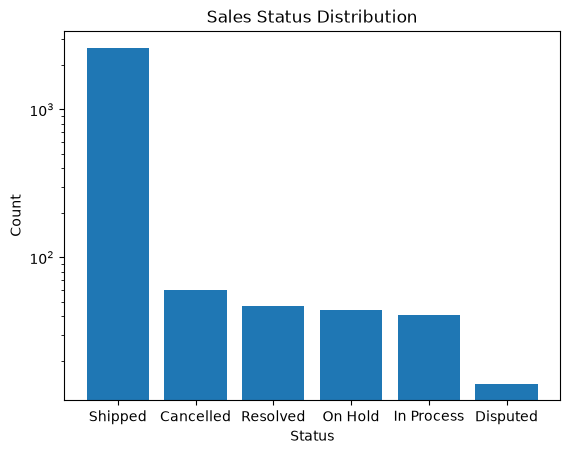

In [94]:
# pie chart
plt.bar(report_df['status'], report_df['counted'])
plt.xlabel('Status')
plt.ylabel('Count')
plt.yscale('log')
plt.title('Sales Status Distribution')
plt.show()
